# 10.1.2 Escoamento horizontal anular

Mesmo duto da secção 10.1.1 (1000 m, D = 0.1 m, 50 elementos, Galerkin) com fechamento de
padrão **anular**: $q_L = 0.5$ kg/s, $q_G$ de 5.0 para 5.5 kg/s em rampa entre 150 e 180 s.
Figuras 10.10 a 10.13. No ficheiro original a fração de gás na entrada tem condição
"conector" sem especificação, que corresponde a gradiente nulo.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from thesis.notebook_utils import thesis_run, compare_states, show_pipe, plot_elements, plot_vertices
from thesis.mf2 import legacy_pipe_dict
from mfsim.plotting import pipe_profiles, compare_runs
from mfsim.runs import load_run

run, res, raw = thesis_run("10.1.2")
compare_states(res, raw)

10.1.2 Escoamento horizontal anular
Mesmo duto com padrão anular fixo. qL=0.5 kg/s; qG sobe de 5.0 para 5.5 kg/s entre 150 e 180 s.
Figuras da tese: Figs. 10.10-10.13
corrida 10_1_2.npz: integrador bdf (rtol 0.01, atol 0.0001, max_step 5.0), 145 instantes de saída até 720 s
duto modelo       var      máx |dif|   faixa MATLAB  dif/faixa
   1 twofluid     alphaG    4.90e-04       1.00e-02   4.88e-02
   1 twofluid     PT        4.94e-04       1.55e-01   3.19e-03
   1 twofluid     qL        8.55e-03       1.02e-01   8.40e-02
   1 twofluid     qG        1.92e-02       5.01e-01   3.83e-02


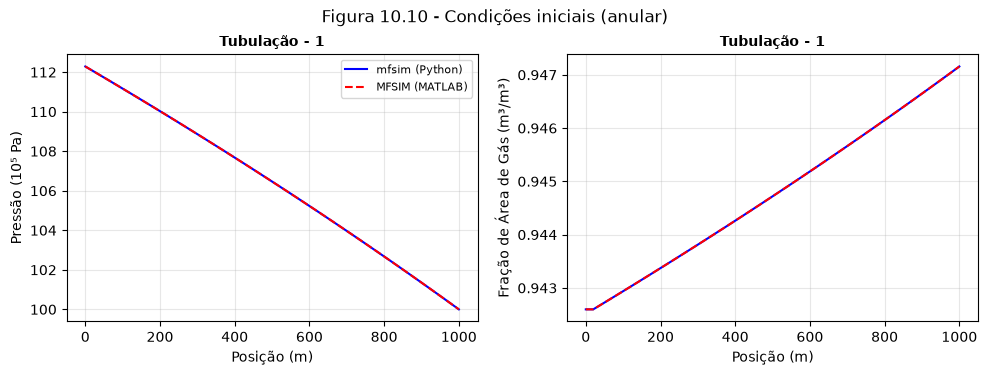

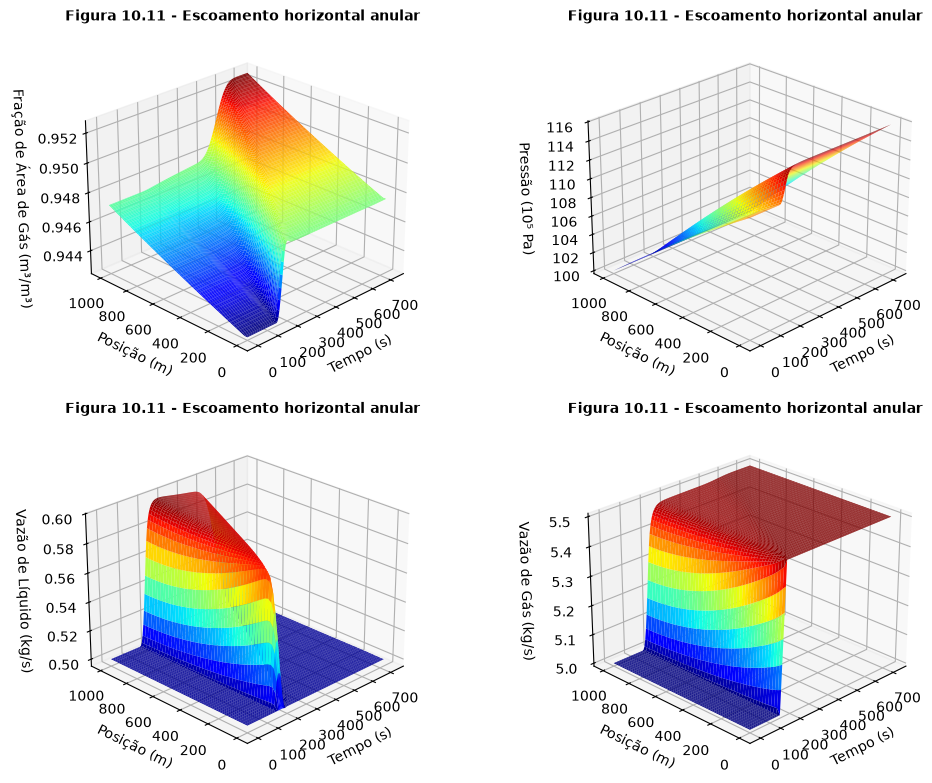

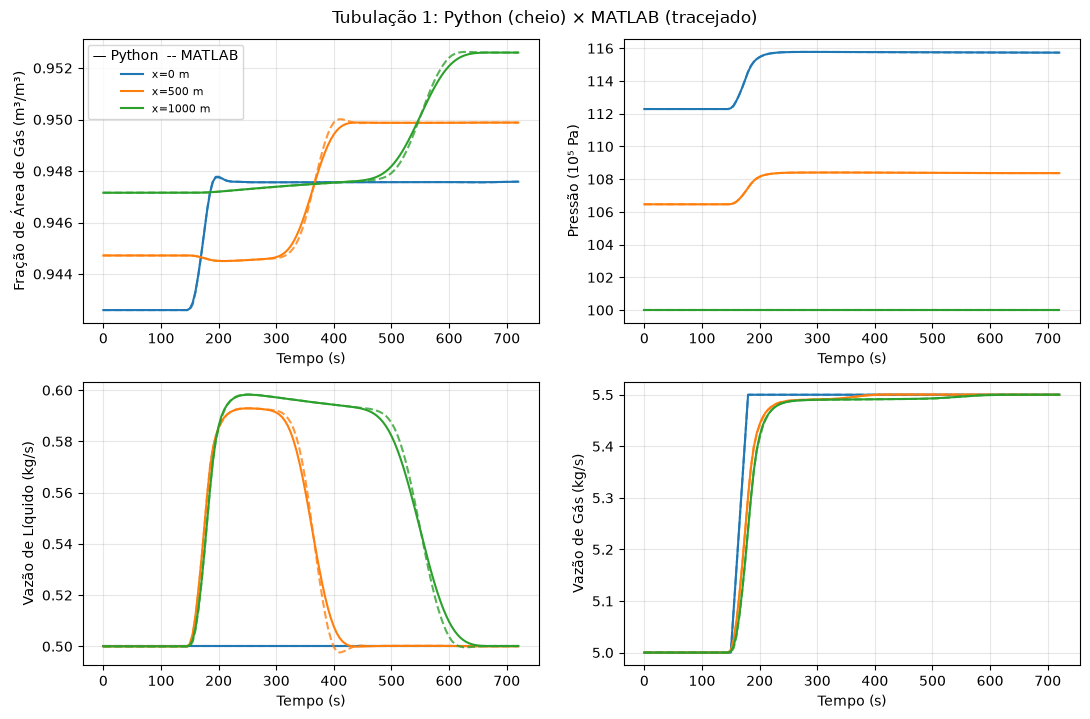

In [2]:
fig = pipe_profiles(res, keys=("P_bar", "alphaG"), it=0, legacy=legacy_pipe_dict(raw, 0))
fig.suptitle("Figura 10.10 - Condições iniciais (anular)", y=1.03)
plt.show()
show_pipe(res, raw, 0, title="Figura 10.11 - Escoamento horizontal anular")

## Sensibilidade de malha (Figuras 10.12 e 10.13)

Para cada malha o estado estacionário é recalculado e a simulação repetida, com o esquema
de Galerkin e com diferenças finitas centrais (corridas `10_1_2_<esquema>_n<N>` do lote). A tese observa que, a partir de 25 elementos, as variáveis praticamente coincidem.

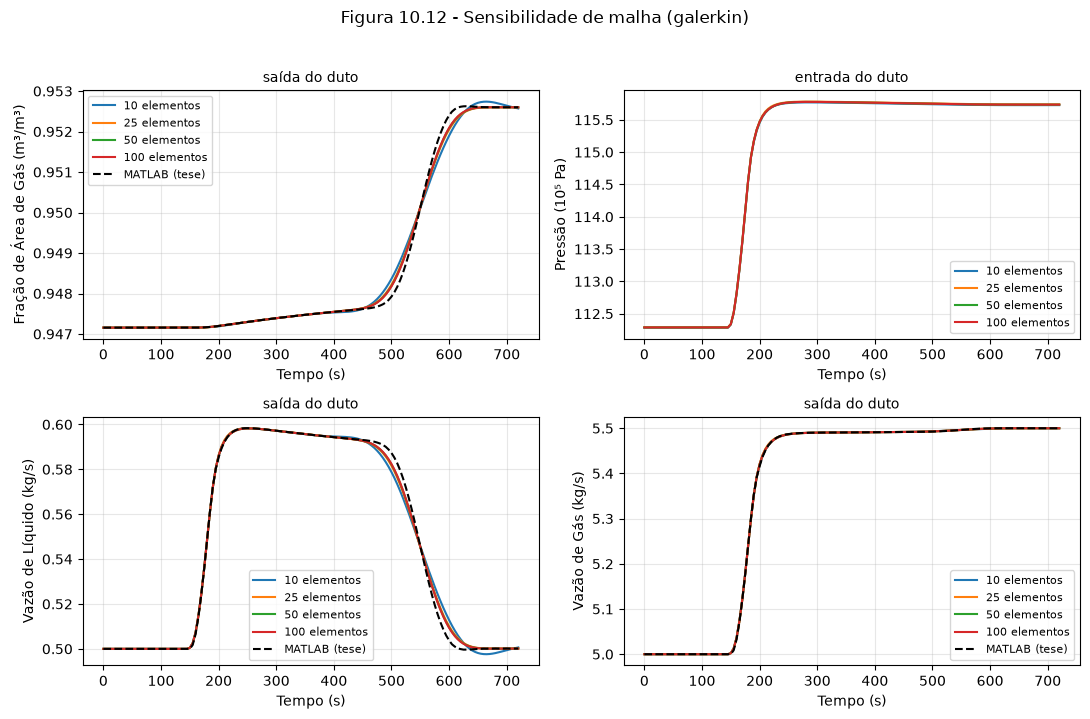

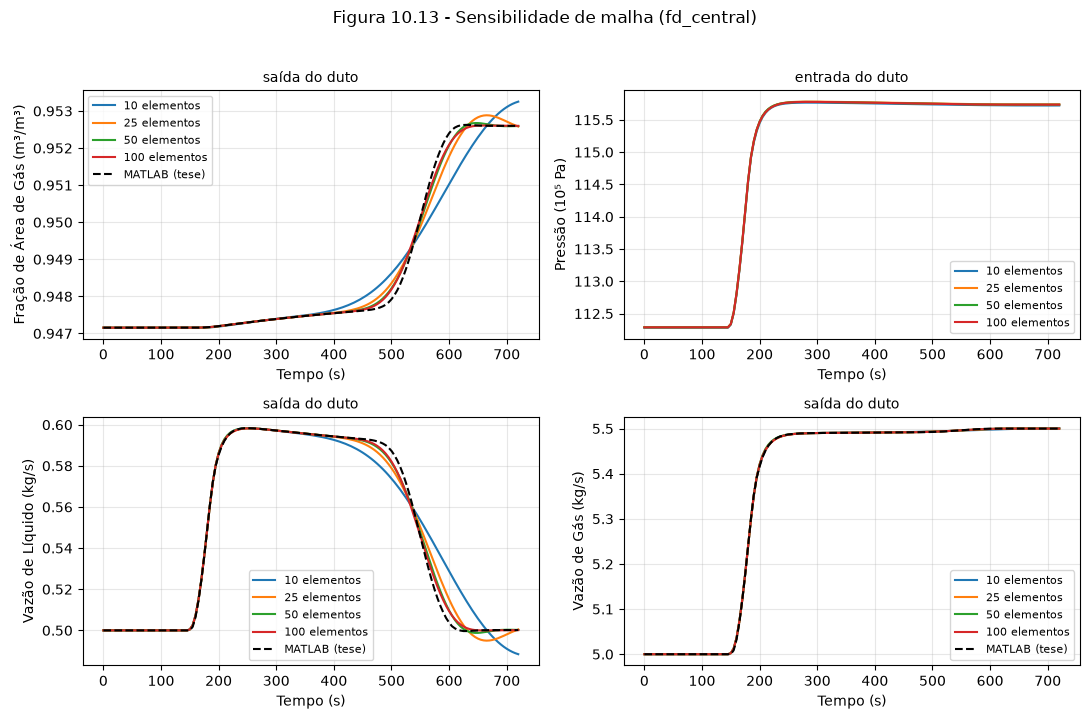

In [3]:
legacy = legacy_pipe_dict(raw, 0)
meshes = [10, 25, 50, 100]
for scheme, fig_no in (("galerkin", "10.12"), ("fd_central", "10.13")):
    runs = {f"{n} elementos": load_run(f"chapter10/10_1_2_{scheme}_n{n}").res for n in meshes}
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    for ax, k_ in zip(axes.ravel(), ["alphaG", "P_bar", "qL", "qG"]):
        compare_runs(
            runs,
            key=k_,
            node=-1 if k_ != "P_bar" else 0,
            ax=ax,
            legacy=legacy if k_ != "P_bar" else None,
            title=f"{'saída' if k_ != 'P_bar' else 'entrada'} do duto",
        )
    fig.suptitle(f"Figura {fig_no} - Sensibilidade de malha ({scheme})", y=1.02)
    fig.tight_layout()
    plt.show()

---
*Notebook de reprodução fiel: nenhuma simulação corre aqui. As corridas vêm do lote
`batches/thesis.json` (`uv run mfsim batch batches/thesis.json`), com a configuração exportada
do ficheiro original; as correções e melhorias estão nos notebooks de `notebooks_src/issues/`
e no índice [docs/issues/INDEX.md](../../docs/issues/INDEX.md).*